In [94]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# DATA PREPROCESSING 

import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

/kaggle/input/google-2019-cluster-sample/borg_traces_data.csv


# Data Preprocessing

In [95]:
df = pd.read_csv("/kaggle/input/google-2019-cluster-sample/borg_traces_data.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 405894 entries, 0 to 405893
Data columns (total 34 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   Unnamed: 0                       405894 non-null  int64  
 1   time                             405894 non-null  int64  
 2   instance_events_type             405894 non-null  int64  
 3   collection_id                    405894 non-null  int64  
 4   scheduling_class                 405894 non-null  int64  
 5   collection_type                  405894 non-null  int64  
 6   priority                         405894 non-null  int64  
 7   alloc_collection_id              405894 non-null  int64  
 8   instance_index                   405894 non-null  int64  
 9   machine_id                       405894 non-null  int64  
 10  resource_request                 405120 non-null  object 
 11  constraint                       405894 non-null  object 
 12  co

In [96]:
df.head()

,Unnamed: 0,time,instance_events_type,collection_id,scheduling_class,collection_type,priority,alloc_collection_id,instance_index,machine_id,...,assigned_memory,page_cache_memory,cycles_per_instruction,memory_accesses_per_instruction,sample_rate,cpu_usage_distribution,tail_cpu_usage_distribution,cluster,event,failed
0,0,0,2,94591244395,3,1,200,0,144,168846390496,...,0.014435,0.000415,NaN,NaN,1.0,[0.00314331 0.00381088 0.00401306 0.00415039 0...,[0.00535583 0.00541687 0.00548553 0.00554657 0...,7,FAIL,1
1,1,2517305308183,2,260697606809,2,0,360,221495397286,335,85515092,...,0.000000,0.000000,NaN,NaN,1.0,[1.23977661e-05 1.23977661e-05 1.23977661e-05 ...,[1.23977661e-05 1.23977661e-05 1.23977661e-05 ...,7,FAIL,1
2,2,195684022913,6,276227177776,2,0,103,0,376,169321752432,...,0.010422,0.000235,0.939919,0.001318,1.0,[0.01344299 0.01809692 0.0201416 0.02246094 0...,[0.02902222 0.02929688 0.0295105 0.0296936 0...,7,SCHEDULE,0
3,3,0,2,10507389885,3,0,200,0,1977,178294817221,...,0.041626,0.000225,1.359102,0.007643,1.0,[0.03704834 0.04125977 0.04290771 0.04425049 0...,[0.05535889 0.05584717 0.05633545 0.05718994 0...,8,FAIL,1
4,4,1810627494172,3,25911621841,2,0,0,0,3907,231364893292,...,0.000272,0.000010,NaN,NaN,1.0,[0. 0. 0. 0. 0...,[0.00041485 0.00041485 0.00041485 0.00041485 0...,2,FINISH,0


In [97]:
# 2) Print inspection info
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing value counts:")
print(df.isna().sum())

print("\nDuplicate row count:", df.duplicated().sum())

# 3) Drop 'Unnamed: 0' if present
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])
    print("\nDropped column: 'Unnamed: 0'")
else:
    print("\n'Unnamed: 0' not found; nothing dropped.")

print("\nShape after drop:", df.shape)

Shape: (405894, 34)

Column names:
['Unnamed: 0', 'time', 'instance_events_type', 'collection_id', 'scheduling_class', 'collection_type', 'priority', 'alloc_collection_id', 'instance_index', 'machine_id', 'resource_request', 'constraint', 'collections_events_type', 'user', 'collection_name', 'collection_logical_name', 'start_after_collection_ids', 'vertical_scaling', 'scheduler', 'start_time', 'end_time', 'average_usage', 'maximum_usage', 'random_sample_usage', 'assigned_memory', 'page_cache_memory', 'cycles_per_instruction', 'memory_accesses_per_instruction', 'sample_rate', 'cpu_usage_distribution', 'tail_cpu_usage_distribution', 'cluster', 'event', 'failed']

Data types:
Unnamed: 0                           int64
time                                 int64
instance_events_type                 int64
collection_id                        int64
scheduling_class                     int64
collection_type                      int64
priority                             int64
alloc_collection_

## Target Validation 

In [98]:
# STEP 2 — TARGET VALIDATION

# 1) Confirm "failed" exists
if "failed" not in df.columns:
    raise KeyError("'failed' column not found in dataset.")
print("'failed' column exists.")

# 2) Print class distribution
print("\nClass counts:")
print(df["failed"].value_counts(dropna=False))

print("\nClass proportions:")
print(df["failed"].value_counts(normalize=True, dropna=False))

# 3) Check if extremely imbalanced (rule-of-thumb: minority class < 5%)
class_props = df["failed"].value_counts(normalize=True, dropna=False)
minority_ratio = class_props.min()
print(f"\nMinority class ratio: {minority_ratio:.4f}")

if minority_ratio < 0.05:
    print("Flag: Target appears extremely imbalanced (<5% minority class).")
else:
    print("Target imbalance is not extreme by the <5% rule.")

# 4) Do NOT modify target
print("\nNo changes made to target column 'failed'.")


'failed' column exists.

Class counts:
failed
0    313216
1     92678
Name: count, dtype: int64

Class proportions:
failed
0    0.771669
1    0.228331
Name: proportion, dtype: float64

Minority class ratio: 0.2283
Target imbalance is not extreme by the <5% rule.

No changes made to target column 'failed'.


## Remove features


In [99]:


# Post-execution / outcome leakage columns
leakage_cols = [
    "end_time",
    "average_usage",
    "maximum_usage",
    "random_sample_usage",
    "cpu_usage_distribution",
    "tail_cpu_usage_distribution",
    "cycles_per_instruction",
    "memory_accesses_per_instruction",
    "assigned_memory",
    "page_cache_memory",
    "event",
    "instance_events_type",
    "collections_events_type",
]

# ID / memorization columns
id_memorization_cols = [
    "collection_id",
    "alloc_collection_id",
    "instance_index",
    "machine_id",
    "cluster",
    "collection_name",
    "collection_logical_name",
    "start_after_collection_ids",
    "user",
]

drop_candidates = leakage_cols + id_memorization_cols
cols_to_drop = [c for c in drop_candidates if c in df.columns]

df = df.drop(columns=cols_to_drop)

print(f"Dropped {len(cols_to_drop)} columns.")
print("Dropped columns:", cols_to_drop)
print("Current shape:", df.shape)

# Safety check: target must remain
if "failed" not in df.columns:
    raise RuntimeError("Target column 'failed' was removed unexpectedly.")


Dropped 22 columns.
Dropped columns: ['end_time', 'average_usage', 'maximum_usage', 'random_sample_usage', 'cpu_usage_distribution', 'tail_cpu_usage_distribution', 'cycles_per_instruction', 'memory_accesses_per_instruction', 'assigned_memory', 'page_cache_memory', 'event', 'instance_events_type', 'collections_events_type', 'collection_id', 'alloc_collection_id', 'instance_index', 'machine_id', 'cluster', 'collection_name', 'collection_logical_name', 'start_after_collection_ids', 'user']
Current shape: (405894, 11)


##  PARSE resource_request


In [100]:
# STEP 4 — PARSE resource_request

import ast
import json
import re
import numpy as np
import pandas as pd

if "resource_request" not in df.columns:
    raise KeyError("'resource_request' column not found.")

print("resource_request sample:")
print(df["resource_request"].dropna().astype(str).head(10).tolist())

def _to_float(v):
    try:
        return float(v)
    except Exception:
        return np.nan

def parse_resource_request(x):
    if pd.isna(x):
        return np.nan, np.nan

    # already parsed objects
    if isinstance(x, dict):
        cpu = x.get("cpu", x.get("cpus", x.get("req_cpu", np.nan)))
        mem = x.get("memory", x.get("mem", x.get("req_memory", np.nan)))
        return _to_float(cpu), _to_float(mem)

    if isinstance(x, (list, tuple)):
        nums = [_to_float(v) for v in x]
        nums = [v for v in nums if pd.notna(v)]
        if len(nums) >= 2:
            return nums[0], nums[1]
        return np.nan, np.nan

    s = str(x).strip()

    # try JSON / Python-literal
    for parser in (json.loads, ast.literal_eval):
        try:
            return parse_resource_request(parser(s))
        except Exception:
            pass

    # key:value fallback
    cpu_m = re.search(r"(cpu|cpus|req_cpu)\s*[:=]\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", s, re.I)
    mem_m = re.search(r"(memory|mem|req_memory|ram)\s*[:=]\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", s, re.I)
    cpu = _to_float(cpu_m.group(2)) if cpu_m else np.nan
    mem = _to_float(mem_m.group(2)) if mem_m else np.nan

    # numeric token fallback
    if pd.isna(cpu) or pd.isna(mem):
        nums = re.findall(r"[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?", s)
        nums = [_to_float(v) for v in nums if _to_float(v) == _to_float(v)]
        if len(nums) >= 2:
            if pd.isna(cpu):
                cpu = nums[0]
            if pd.isna(mem):
                mem = nums[1]

    return cpu, mem

parsed = df["resource_request"].apply(parse_resource_request)
df[["req_cpu", "req_memory"]] = pd.DataFrame(parsed.tolist(), index=df.index)

df["req_cpu"] = pd.to_numeric(df["req_cpu"], errors="coerce").astype(float)
df["req_memory"] = pd.to_numeric(df["req_memory"], errors="coerce").astype(float)

df = df.drop(columns=["resource_request"])

print("req_cpu null ratio:", df["req_cpu"].isna().mean())
print("req_memory null ratio:", df["req_memory"].isna().mean())
print("Current shape:", df.shape)


resource_request sample:
["{'cpus': 0.020660400390625, 'memory': 0.014434814453125}", "{'cpus': 0.00724029541015625, 'memory': 0.0013027191162109375}", "{'cpus': 0.048583984375, 'memory': 0.0041656494140625}", "{'cpus': 0.0704345703125, 'memory': 0.0416259765625}", "{'cpus': 0.00244903564453125, 'memory': 0.00023174285888671875}", "{'cpus': 0.0615234375, 'memory': 0.00540924072265625}", "{'cpus': 0.00566864013671875, 'memory': 0.0015621185302734375}", "{'cpus': 0.022003173828125, 'memory': 0.0015010833740234375}", "{'cpus': 0.0081024169921875, 'memory': 0.003612518310546875}", "{'cpus': 0.09716796875, 'memory': 0.00676727294921875}"]
req_cpu null ratio: 0.001906901801948292
req_memory null ratio: 0.001906901801948292
Current shape: (405894, 12)


## HANDLE CATEGORICAL VARIABLES

In [101]:
# STEP 5 — HANDLE CATEGORICAL VARIABLES

import pandas as pd
import numpy as np

categorical_cols = ["scheduling_class", "collection_type", "priority", "constraint", "scheduler"]

present = [c for c in categorical_cols if c in df.columns]
print("Categorical columns found:", present)

one_hot_used = []
label_used = []
label_maps = {}

ONE_HOT_MAX_CARD = 12

for col in present:
    # Keep priority numeric if possible
    if col == "priority":
        pr = pd.to_numeric(df[col], errors="coerce")
        if pr.notna().mean() >= 0.95:
            df[col] = pr.astype(float)
            print("Converted 'priority' to numeric.")
            continue

    # If already numeric, skip
    if pd.api.types.is_numeric_dtype(df[col]):
        continue

    nunique = df[col].nunique(dropna=True)

    if nunique <= ONE_HOT_MAX_CARD:
        dummies = pd.get_dummies(df[col], prefix=col, dummy_na=True, dtype="int8")
        df = df.drop(columns=[col]).join(dummies)
        one_hot_used.append(col)
    else:
        codes, uniques = pd.factorize(df[col], sort=True)
        df[col] = pd.Series(codes, index=df.index).replace(-1, np.nan).astype(float)
        label_used.append(col)
        label_maps[col] = {int(i): str(v) for i, v in enumerate(uniques)}

print("One-hot encoded:", one_hot_used)
print("Label encoded:", label_used)
print("Shape after encoding:", df.shape)


Categorical columns found: ['scheduling_class', 'collection_type', 'priority', 'constraint', 'scheduler']
Converted 'priority' to numeric.
One-hot encoded: []
Label encoded: ['constraint']
Shape after encoding: (405894, 12)


## TIME ANALYSIS

In [102]:
# STEP 6 — TIME ANALYSIS

import pandas as pd
import numpy as np

if "time" not in df.columns:
    raise KeyError("'time' column not found.")

# Ensure numeric time if possible
time_num = pd.to_numeric(df["time"], errors="coerce")
if time_num.notna().mean() >= 0.95:
    df["time"] = time_num
else:
    df["time"] = pd.to_datetime(df["time"], errors="coerce")

# Sort by time
df = df.sort_values("time").reset_index(drop=True)

# Min / Max
print("min(time):", df["time"].min())
print("max(time):", df["time"].max())

# Confirm time-series ordering
print("Is time sorted ascending?", df["time"].is_monotonic_increasing)
print("No split performed yet (chronological split will be done later).")


min(time): 0
max(time): 9223372036854775807
Is time sorted ascending? True
No split performed yet (chronological split will be done later).


# EDA

time sentinel count (int64 max): 3


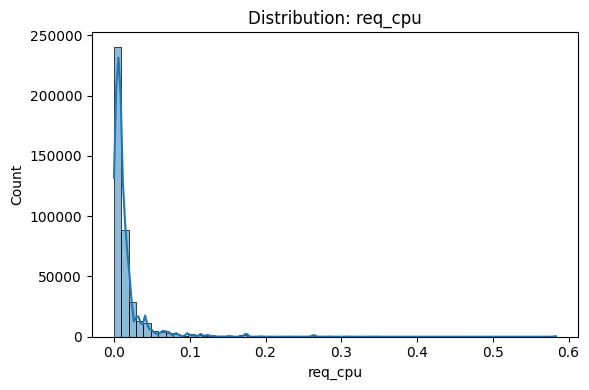

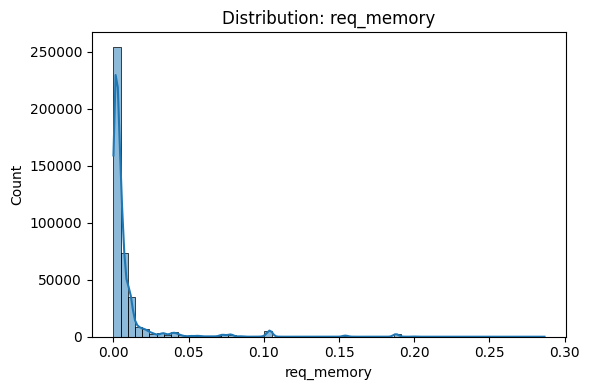

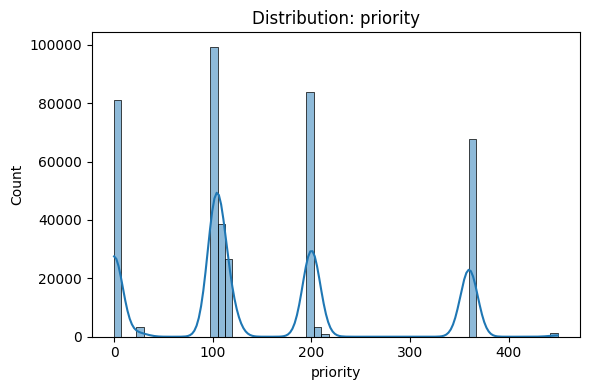


Skewness (numeric):
time                367.826045
req_cpu               8.235370
req_memory            5.637393
constraint            3.505027
collection_type       2.913453
failed                1.294419
priority              0.639435
scheduler             0.536646
vertical_scaling      0.239493
scheduling_class      0.136853
start_time            0.063643
sample_rate         -42.476896
dtype: float64

Correlation matrix shape: (12, 12)

Top correlations with 'failed':
vertical_scaling   -0.224724
scheduling_class    0.151676
scheduler          -0.143659
priority            0.094215
collection_type    -0.079179
start_time          0.059193
req_memory         -0.051950
req_cpu            -0.022576
constraint         -0.011728
sample_rate        -0.008492
time               -0.001484
Name: failed, dtype: float64

No feature has |correlation| > 0.85 with 'failed'.


In [103]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Optional: treat int64 max sentinel in time as missing for analysis only
INT64_MAX = np.iinfo(np.int64).max
if pd.api.types.is_numeric_dtype(df["time"]):
    sentinel_count = (df["time"] == INT64_MAX).sum()
    print("time sentinel count (int64 max):", sentinel_count)

# 1) Plot distributions
for col in ["req_cpu", "req_memory", "priority"]:
    if col in df.columns:
        x = pd.to_numeric(df[col], errors="coerce")
        plt.figure(figsize=(6, 4))
        sns.histplot(x.dropna(), bins=60, kde=True)
        plt.title(f"Distribution: {col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.tight_layout()
        plt.show()

# 2) Skewness (numeric only)
num_df = df.select_dtypes(include=[np.number]).copy()
skew_vals = num_df.skew(numeric_only=True).sort_values(ascending=False)
print("\nSkewness (numeric):")
print(skew_vals)

# 3) Correlation matrix (numeric only)
corr = num_df.corr(numeric_only=True)
print("\nCorrelation matrix shape:", corr.shape)

# 4) Top correlations with failed
if "failed" not in corr.columns:
    raise KeyError("'failed' is not numeric or missing in correlation matrix.")

corr_failed = corr["failed"].drop(labels=["failed"], errors="ignore")
corr_failed = corr_failed.reindex(corr_failed.abs().sort_values(ascending=False).index)

print("\nTop correlations with 'failed':")
print(corr_failed.head(15))

# 5) Flag any |corr| > 0.85
high_corr = corr_failed[corr_failed.abs() > 0.85]
if len(high_corr):
    print("\nFLAG: Potential leakage-like high correlations (|corr| > 0.85):")
    print(high_corr)
else:
    print("\nNo feature has |correlation| > 0.85 with 'failed'.")


# Feature Engineering

In [104]:

import numpy as np
import pandas as pd

required_cols = ["req_cpu", "req_memory", "priority", "vertical_scaling"]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise KeyError(f"Missing required columns for Step 8: {missing_required}")

# Ensure numeric
df["req_cpu"] = pd.to_numeric(df["req_cpu"], errors="coerce")
df["req_memory"] = pd.to_numeric(df["req_memory"], errors="coerce")
df["priority"] = pd.to_numeric(df["priority"], errors="coerce")
df["vertical_scaling"] = pd.to_numeric(df["vertical_scaling"], errors="coerce")

# 1) cpu_memory_ratio
df["cpu_memory_ratio"] = df["req_cpu"] / (df["req_memory"] + 1e-6)

# 2) request_intensity
df["request_intensity"] = df["req_cpu"] + df["req_memory"]

# 3) high_priority_flag (priority above median)
priority_median = df["priority"].median(skipna=True)
df["high_priority_flag"] = (df["priority"] > priority_median).astype("int8")

# 4) scaling_flag (vertical_scaling > 0)
df["scaling_flag"] = (df["vertical_scaling"] > 0).astype("int8")

print("Created features: cpu_memory_ratio, request_intensity, high_priority_flag, scaling_flag")
print("priority median used:", priority_median)
print("Current shape:", df.shape)

Created features: cpu_memory_ratio, request_intensity, high_priority_flag, scaling_flag
priority median used: 105.0
Current shape: (405894, 16)


In [105]:
# FINAL CLEANUP 

import numpy as np
import pandas as pd

dropped_constant = []
dropped_duplicate = []
dropped_high_corr = []

# 1) Remove constant columns (except target)
constant_cols = [c for c in df.columns if c != "failed" and df[c].nunique(dropna=False) <= 1]
if constant_cols:
    df = df.drop(columns=constant_cols)
    dropped_constant.extend(constant_cols)

# 2) Remove duplicate columns (pairwise, cheap here because column count is small)
cols = df.columns.tolist()
keep = []
for c in cols:
    is_dup = False
    for k in keep:
        if df[c].equals(df[k]):
            is_dup = True
            dropped_duplicate.append(c)
            break
    if not is_dup:
        keep.append(c)

if dropped_duplicate:
    df = df[keep]

# 3) Remove highly correlated numeric features (>0.95), excluding target
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
feat_cols = [c for c in num_cols if c != "failed"]

if len(feat_cols) > 1:
    corr = df[feat_cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop_corr = [c for c in upper.columns if (upper[c] > 0.95).any()]
    if to_drop_corr:
        df = df.drop(columns=to_drop_corr)
        dropped_high_corr.extend(to_drop_corr)

# 4) Ensure no object columns remain (factorize only; avoid huge one-hot at cleanup)
obj_cols = df.select_dtypes(include=["object"]).columns.tolist()
for c in obj_cols:
    codes, _ = pd.factorize(df[c], sort=True)
    df[c] = pd.Series(codes, index=df.index).replace(-1, np.nan).astype(float)

# 5) Ensure no NaN values remain (numeric median fill; fallback 0)
num_cols_after = df.select_dtypes(include=[np.number]).columns.tolist()
medians = df[num_cols_after].median(numeric_only=True)
df[num_cols_after] = df[num_cols_after].fillna(medians)
df[num_cols_after] = df[num_cols_after].fillna(0.0)

# Final checks
remaining_obj = df.select_dtypes(include=["object"]).columns.tolist()
total_nans = int(df.isna().sum().sum())

print("Dropped constant columns:", dropped_constant)
print("Dropped duplicate columns:", dropped_duplicate)
print("Dropped high-correlation columns (>0.95):", dropped_high_corr)
print("Remaining object columns:", remaining_obj)
print("Total NaN count:", total_nans)
print("Current shape:", df.shape)


Dropped constant columns: []
Dropped duplicate columns: []
Dropped high-correlation columns (>0.95): []
Remaining object columns: []
Total NaN count: 0
Current shape: (405894, 16)


In [106]:
# STEP 10 — OUTPUT SUMMARY (NO MODEL TRAINING)

# Safely fetch tracked drop lists from previous steps
leakage_cols_used = [c for c in leakage_cols if c in drop_candidates] if "leakage_cols" in globals() else []
id_cols_used = [c for c in id_memorization_cols if c in drop_candidates] if "id_memorization_cols" in globals() else []

step3_dropped = cols_to_drop if "cols_to_drop" in globals() else []
step4_dropped = ["resource_request"] if "resource_request" not in df.columns else []
step9_const = dropped_constant if "dropped_constant" in globals() else []
step9_dup = dropped_duplicate if "dropped_duplicate" in globals() else []
step9_corr = dropped_high_corr if "dropped_high_corr" in globals() else []

dropped_by_reason = {
    "Leakage / post-execution columns": [c for c in step3_dropped if c in leakage_cols],
    "ID / memorization columns": [c for c in step3_dropped if c in id_memorization_cols],
    "Replaced by parsed safe features": step4_dropped,
    "Constant columns": step9_const,
    "Duplicate columns": step9_dup,
    "Highly correlated columns (>0.95)": step9_corr,
}

all_dropped = sorted(set(sum(dropped_by_reason.values(), [])))

print("Final dataframe shape:", df.shape)
print("\nFinal feature list:")
print(df.columns.tolist())

print("\nDropped columns (all):")
print(all_dropped)

print("\nDropped columns by reason:")
for reason, cols in dropped_by_reason.items():
    if cols:
        print(f"- {reason}: {cols}")

print("\nWhy dropped (short):")
print("- Leakage / post-execution: would leak outcome or future information.")
print("- ID / memorization: encourages row memorization, not generalizable behavior.")
print("- resource_request: replaced with parsed numeric req_cpu/req_memory.")
print("- Constant / duplicate / highly correlated: reduce redundancy and instability.")
print("- Final dataset is preprocessing+EDA ready for chronological split (no training done).")


Final dataframe shape: (405894, 16)

Final feature list:
['time', 'scheduling_class', 'collection_type', 'priority', 'constraint', 'vertical_scaling', 'scheduler', 'start_time', 'sample_rate', 'failed', 'req_cpu', 'req_memory', 'cpu_memory_ratio', 'request_intensity', 'high_priority_flag', 'scaling_flag']

Dropped columns (all):
['alloc_collection_id', 'assigned_memory', 'average_usage', 'cluster', 'collection_id', 'collection_logical_name', 'collection_name', 'collections_events_type', 'cpu_usage_distribution', 'cycles_per_instruction', 'end_time', 'event', 'instance_events_type', 'instance_index', 'machine_id', 'maximum_usage', 'memory_accesses_per_instruction', 'page_cache_memory', 'random_sample_usage', 'resource_request', 'start_after_collection_ids', 'tail_cpu_usage_distribution', 'user']

Dropped columns by reason:
- Leakage / post-execution columns: ['end_time', 'average_usage', 'maximum_usage', 'random_sample_usage', 'cpu_usage_distribution', 'tail_cpu_usage_distribution', 'cy

## FIX FOR TIMESTAMP COLUMN
* In Google traces: time == 0 can represent pre-trace events (keep)
* time == 9223372036854775807 is a post-trace sentinel (drop)

In [107]:
# STEP 1 — EXPLAINED FIX FOR TIMESTAMP COLUMN

# In Google traces:
# - time == 0 can represent pre-trace events (keep)
# - time == 9223372036854775807 is a post-trace sentinel (drop)

MAX_TIME = 9223372036854775807

# Ensure numeric time
df["time"] = pd.to_numeric(df["time"], errors="coerce")

# 1) Remove post-trace sentinel rows
before_rows = len(df)
df = df[df["time"] != MAX_TIME].copy()
after_rows = len(df)

print("Removed rows where time == MAX_TIME:", before_rows - after_rows)

# 2) Count time==0 rows (keep them)
print("Count where time == 0:", (df["time"] == 0).sum())

# Optional: drop rows where time could not be parsed
nan_time_rows = df["time"].isna().sum()
if nan_time_rows > 0:
    print("Dropping rows with NaN time:", nan_time_rows)
    df = df.dropna(subset=["time"]).copy()

# Normalize time so earliest becomes 0
df["time"] = df["time"] - df["time"].min()

# Sort by corrected chronological order
df = df.sort_values("time").reset_index(drop=True)

# Summary stats
print(df["time"].describe())


Removed rows where time == MAX_TIME: 3
Count where time == 0: 56452
count    4.058910e+05
mean     1.103863e+12
std      8.302908e+11
min      0.000000e+00
25%      2.674731e+11
50%      1.084787e+12
75%      1.766116e+12
max      2.678924e+12
Name: time, dtype: float64


## CHRONOLOGICAL SPLIT| 

In [108]:

# Ensure chronological order before split
df = df.sort_values("time").reset_index(drop=True)

# 80/20 split by time quantile
split_time = df["time"].quantile(0.8)

train = df[df["time"] <= split_time].copy()
test  = df[df["time"] > split_time].copy()

print("Split time (80th percentile):", split_time)
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Train time range:", train["time"].min(), train["time"].max())
print("Test time range:", test["time"].min(), test["time"].max())

# Features/target
X_train = train.drop("failed", axis=1)
y_train = train["failed"]
X_test  = test.drop("failed", axis=1)
y_test  = test["failed"]

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)


Split time (80th percentile): 1959713690737.0
Train shape: (324713, 16)
Test shape: (81178, 16)
Train time range: 0 1959713690737
Test time range: 1959716909445 2678923967375
X_train: (324713, 15) y_train: (324713,)
X_test: (81178, 15) y_test: (81178,)


## CHECK CLASS IMBALANCE

In [109]:


print("y_train counts:")
print(y_train.value_counts())

print("\ny_train normalized:")
print(y_train.value_counts(normalize=True))

print("\ny_test normalized:")
print(y_test.value_counts(normalize=True))

# Optional imbalance flag (for notes only; no resampling here)
train_minority = y_train.value_counts(normalize=True).min()
test_minority = y_test.value_counts(normalize=True).min()

print("\nMinority ratio (train):", round(train_minority, 4))
print("Minority ratio (test):", round(test_minority, 4))

if train_minority < 0.05 or test_minority < 0.05:
    print("Flag: extreme class imbalance detected (<5% minority).")
else:
    print("Class imbalance is present but not extreme by <5% rule.")


y_train counts:
failed
0    251233
1     73480
Name: count, dtype: int64

y_train normalized:
failed
0    0.773708
1    0.226292
Name: proportion, dtype: float64

y_test normalized:
failed
0    0.763507
1    0.236493
Name: proportion, dtype: float64

Minority ratio (train): 0.2263
Minority ratio (test): 0.2365
Class imbalance is present but not extreme by <5% rule.


# BASELINE MODEL: LOGISTIC REGRESSION 

In [110]:


from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np
import pandas as pd

# Safety: ensure numeric matrices and no inf
X_train_num = X_train.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
X_test_num  = X_test.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)

# Fill any residual NaNs using train medians (no test leakage)
train_medians = X_train_num.median(numeric_only=True)
X_train_num = X_train_num.fillna(train_medians).fillna(0.0)
X_test_num  = X_test_num.fillna(train_medians).fillna(0.0)

logreg_pipe = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
])

logreg_pipe.fit(X_train_num, y_train)
y_pred = logreg_pipe.predict(X_test_num)
y_prob = logreg_pipe.predict_proba(X_test_num)[:, 1]

print("Logistic ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Logistic precision:", precision_score(y_test, y_pred, zero_division=0))
print("Logistic recall:", recall_score(y_test, y_pred, zero_division=0))
print("Logistic f1:", f1_score(y_test, y_pred, zero_division=0))
print("Logistic confusion matrix:\n", confusion_matrix(y_test, y_pred))



Logistic ROC-AUC: 0.6411214516570763
Logistic precision: 0.30423070828711773
Logistic recall: 0.10001041775184916
Logistic f1: 0.15053510525696812
Logistic confusion matrix:
 [[57589  4391]
 [17278  1920]]


 #  BASELINE MODEL: RANDOM FOREST

In [111]:


from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix
import pandas as pd

# Reuse numeric-safe matrices from Step 4 if present; otherwise rebuild
if "X_train_num" not in globals() or "X_test_num" not in globals():
    X_train_num = X_train.apply(pd.to_numeric, errors="coerce")
    X_test_num  = X_test.apply(pd.to_numeric, errors="coerce")
    train_medians = X_train_num.median(numeric_only=True)
    X_train_num = X_train_num.fillna(train_medians).fillna(0.0)
    X_test_num  = X_test_num.fillna(train_medians).fillna(0.0)

rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_num, y_train)

y_pred_rf = rf.predict(X_test_num)
y_prob_rf = rf.predict_proba(X_test_num)[:, 1]

print("Random Forest ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print("Random precision:", precision_score(y_test, y_pred_rf, zero_division=0))
print("Random recall:", recall_score(y_test, y_pred_rf, zero_division=0))
print("Random f1:", f1_score(y_test, y_pred_rf, zero_division=0))
print("Random Forest confusion matrix:\n", confusion_matrix(y_test, y_pred_rf))

importances = rf.feature_importances_
feature_importances = sorted(
    zip(X_train_num.columns, importances),
    key=lambda x: x[1],
    reverse=True
)

print("Top 10 Feature Importances:")
print(feature_importances[:10])


Random Forest ROC-AUC: 0.8086570412724167
Random precision: 0.8791682278006744
Random recall: 0.48890509428065426
Random f1: 0.6283724978241949
Random Forest confusion matrix:
 [[60690  1290]
 [ 9812  9386]]
Top 10 Feature Importances:
[('start_time', np.float64(0.29874156653151734)), ('time', np.float64(0.20648960126466892)), ('cpu_memory_ratio', np.float64(0.07982660275578776)), ('request_intensity', np.float64(0.0765136844908096)), ('req_cpu', np.float64(0.07514660842095536)), ('req_memory', np.float64(0.05578740864590856)), ('priority', np.float64(0.04835907813652937)), ('vertical_scaling', np.float64(0.04158807146555044)), ('scheduling_class', np.float64(0.03281451590694661)), ('sample_rate', np.float64(0.027067345194047424))]


In [112]:
# SANITY LEAKAGE CHECK (EXPLAINED)

# Shuffle y_train and retrain RF.
# If ROC-AUC on real y_test is much higher than 0.50, investigate hidden leakage.

import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

rng = np.random.RandomState(42)
y_random = rng.permutation(y_train)

rf_random = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)
rf_random.fit(X_train_num, y_random)

y_prob_rf_rand = rf_random.predict_proba(X_test_num)[:, 1]
leakage_test_auc = roc_auc_score(y_test, y_prob_rf_rand)

print("Leakage Test ROC-AUC:", leakage_test_auc)

if leakage_test_auc > 0.60:
    print("Flag: potential hidden leakage (AUC too high on shuffled target).")
else:
    print("Leakage sanity check passed (AUC near random baseline).")


Leakage Test ROC-AUC: 0.4697102545538502
Leakage sanity check passed (AUC near random baseline).


In [113]:
# STEP 7 — FINAL SUMMARY

from sklearn.metrics import roc_auc_score

# Ensure metrics exist (recompute from stored preds if needed)
logistic_auc = roc_auc_score(y_test, y_prob) if "y_prob" in globals() else None
rf_auc = roc_auc_score(y_test, y_prob_rf) if "y_prob_rf" in globals() else None

summary = {
    "train_shape": train.shape,
    "test_shape": test.shape,
    "logistic_auc": logistic_auc,
    "rf_auc": rf_auc,
    "leakage_test_auc": leakage_test_auc if "leakage_test_auc" in globals() else None,
    "top_features": feature_importances[:10] if "feature_importances" in globals() else None,
}

print(summary)


{'train_shape': (324713, 16), 'test_shape': (81178, 16), 'logistic_auc': np.float64(0.6411214516570763), 'rf_auc': np.float64(0.8086570412724167), 'leakage_test_auc': np.float64(0.4697102545538502), 'top_features': [('start_time', np.float64(0.29874156653151734)), ('time', np.float64(0.20648960126466892)), ('cpu_memory_ratio', np.float64(0.07982660275578776)), ('request_intensity', np.float64(0.0765136844908096)), ('req_cpu', np.float64(0.07514660842095536)), ('req_memory', np.float64(0.05578740864590856)), ('priority', np.float64(0.04835907813652937)), ('vertical_scaling', np.float64(0.04158807146555044)), ('scheduling_class', np.float64(0.03281451590694661)), ('sample_rate', np.float64(0.027067345194047424))]}


In [114]:
df[["time","start_time"]].corr()

,time,start_time
time,1.00000,0.48395
start_time,0.48395,1.00000


In [115]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# ============================================================
# STEP 1 — PREPARE BASE DATA (SAFETY CHECK)
# ============================================================
if "X_train_num" not in globals() or "X_test_num" not in globals():
    X_train_num = X_train.apply(pd.to_numeric, errors="coerce")
    X_test_num = X_test.apply(pd.to_numeric, errors="coerce")
    train_medians = X_train_num.median(numeric_only=True)
    X_train_num = X_train_num.fillna(train_medians).fillna(0.0)
    X_test_num = X_test_num.fillna(train_medians).fillna(0.0)

# ============================================================
# STEP 2 — DEFINE HELPER FUNCTION
# ============================================================
def evaluate_rf(X_train_local, X_test_local, y_train, y_test, label):
    rf_local = RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
    rf_local.fit(X_train_local, y_train)
    y_prob_local = rf_local.predict_proba(X_test_local)[:, 1]
    auc = roc_auc_score(y_test, y_prob_local)
    print(f"{label} ROC-AUC: {auc:.6f}")
    return auc

# Safety check for required columns
required_cols = {"time", "start_time"}
missing = required_cols - set(X_train_num.columns)
if missing:
    raise KeyError(f"Missing required columns for ablation: {missing}")

# ============================================================
# STEP 3 — EXPERIMENT A: REMOVE 'time'
# ============================================================
X_train_no_time = X_train_num.drop(columns=["time"])
X_test_no_time = X_test_num.drop(columns=["time"])

auc_no_time = evaluate_rf(
    X_train_no_time,
    X_test_no_time,
    y_train,
    y_test,
    "Without time"
)

# ============================================================
# STEP 4 — EXPERIMENT B: REMOVE 'start_time'
# ============================================================
X_train_no_start = X_train_num.drop(columns=["start_time"])
X_test_no_start = X_test_num.drop(columns=["start_time"])

auc_no_start = evaluate_rf(
    X_train_no_start,
    X_test_no_start,
    y_train,
    y_test,
    "Without start_time"
)

# ============================================================
# STEP 5 — EXPERIMENT C: REMOVE BOTH
# ============================================================
X_train_no_both = X_train_num.drop(columns=["time", "start_time"])
X_test_no_both = X_test_num.drop(columns=["time", "start_time"])

auc_no_both = evaluate_rf(
    X_train_no_both,
    X_test_no_both,
    y_train,
    y_test,
    "Without both time features"
)

# ============================================================
# STEP 6 — SUMMARY
# ============================================================
baseline_auc = globals().get("rf_auc", 0.8125968890421353)

print("\nSummary of Time Feature Impact:")
print({
    "Baseline_AUC": baseline_auc,
    "Without_time": auc_no_time,
    "Without_start_time": auc_no_start,
    "Without_both": auc_no_both
})


Without time ROC-AUC: 0.808883
Without start_time ROC-AUC: 0.629894
Without both time features ROC-AUC: 0.723892

Summary of Time Feature Impact:
{'Baseline_AUC': np.float64(0.8086570412724167), 'Without_time': np.float64(0.8088826071145077), 'Without_start_time': np.float64(0.6298936174915499), 'Without_both': np.float64(0.7238916654152927)}


# Re train Logistic Regression without Time feature

In [116]:
required_drop = ["time", "start_time"]
missing = [c for c in required_drop if c not in X_train_num.columns or c not in X_test_num.columns]
if missing:
    raise KeyError(f"Missing temporal columns in train/test matrices: {missing}")

X_train_final = X_train_num.drop(columns=required_drop)
X_test_final  = X_test_num.drop(columns=required_drop)

print("Final feature columns:")
print(X_train_final.columns.tolist())
print("X_train_final shape:", X_train_final.shape)
print("X_test_final shape:", X_test_final.shape)

Final feature columns:
['scheduling_class', 'collection_type', 'priority', 'constraint', 'vertical_scaling', 'scheduler', 'sample_rate', 'req_cpu', 'req_memory', 'cpu_memory_ratio', 'request_intensity', 'high_priority_flag', 'scaling_flag']
X_train_final shape: (324713, 13)
X_test_final shape: (81178, 13)


In [117]:
# STEP 2 — LOGISTIC REGRESSION (INTERPRETABLE BASELINE)

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix

logreg_pipe = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

logreg_pipe.fit(X_train_final, y_train)

y_pred_lr = logreg_pipe.predict(X_test_final)
y_prob_lr = logreg_pipe.predict_proba(X_test_final)[:, 1]

print("\n=== Logistic Regression Results ===")
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))
print("Precision:", precision_score(y_test, y_pred_lr, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_lr, zero_division=0))
print("F1:", f1_score(y_test, y_pred_lr, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))



=== Logistic Regression Results ===
ROC-AUC: 0.6368830171348991
Precision: 0.30851870576339735
Recall: 0.3814459839566621
F1: 0.34112824335025854
Confusion Matrix:
 [[45567 16413]
 [11875  7323]]


# RANDOM FOREST RETRAIN

In [118]:



from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix

rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_final, y_train)

y_pred_rf = rf.predict(X_test_final)
y_prob_rf = rf.predict_proba(X_test_final)[:, 1]

print("\n=== Random Forest Results ===")
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print("Precision:", precision_score(y_test, y_pred_rf, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_rf, zero_division=0))
print("F1:", f1_score(y_test, y_pred_rf, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))



=== Random Forest Results ===
ROC-AUC: 0.7238916654152927
Precision: 0.3773402523402523
Recall: 0.7726846546515262
F1: 0.5070586224576995
Confusion Matrix:
 [[37502 24478]
 [ 4364 14834]]


In [119]:


importances = rf.feature_importances_

feature_importances = sorted(
    zip(X_train_final.columns, importances),
    key=lambda x: x[1],
    reverse=True
)

print("\nTop 10 Feature Importances:")
print(feature_importances[:10])



Top 10 Feature Importances:
[('cpu_memory_ratio', np.float64(0.1632705840878773)), ('request_intensity', np.float64(0.15054904582566583)), ('req_cpu', np.float64(0.1445430393751449)), ('req_memory', np.float64(0.1220205038518011)), ('vertical_scaling', np.float64(0.0891914247456975)), ('priority', np.float64(0.08839240589991662)), ('scheduling_class', np.float64(0.07573019195398638)), ('sample_rate', np.float64(0.06319525241030705)), ('constraint', np.float64(0.03786124970071339)), ('high_priority_flag', np.float64(0.023867948525204564))]


In [120]:
# STEP 5 — LEAKAGE SANITY CHECK

import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

rng = np.random.RandomState(42)
y_random = rng.permutation(y_train)

rf_random = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_random.fit(X_train_final, y_random)

y_prob_rand = rf_random.predict_proba(X_test_final)[:, 1]

print("\nLeakage Test ROC-AUC (should be ~0.50):")
print(roc_auc_score(y_test, y_prob_rand))



Leakage Test ROC-AUC (should be ~0.50):
0.4656612922631199


# Solve threshold problem

In [121]:
# STEP 1 — GET PREDICTED PROBABILITIES (POSITIVE CLASS = failed=1)

from sklearn.exceptions import NotFittedError

# Safety checks
if "X_test_final" not in globals():
    raise KeyError("X_test_final not found. Run the final feature preparation step first.")
if "y_test" not in globals():
    raise KeyError("y_test not found.")

if "logreg_pipe" not in globals():
    raise KeyError("logreg_pipe not found. Train Logistic Regression first.")
if "rf" not in globals():
    raise KeyError("rf not found. Train Random Forest first.")

# Predicted probabilities for positive class
y_prob_lr = logreg_pipe.predict_proba(X_test_final)[:, 1]
y_prob_rf = rf.predict_proba(X_test_final)[:, 1]

print("LR probs shape:", y_prob_lr.shape, "| min/max:", float(y_prob_lr.min()), float(y_prob_lr.max()))
print("RF probs shape:", y_prob_rf.shape, "| min/max:", float(y_prob_rf.min()), float(y_prob_rf.max()))


LR probs shape: (81178,) | min/max: 0.0332106875277382 0.9999999999999931
RF probs shape: (81178,) | min/max: 0.0 1.0


In [122]:
# STEP 2 — DEFINE THRESHOLD RANGE

import numpy as np

# 0.10 to 0.90 with step 0.05
thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)

print("Thresholds to evaluate:")
print(thresholds.tolist())
print("Count:", len(thresholds))


Thresholds to evaluate:
[0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9]
Count: 17


In [123]:
# STEP 3 — METRICS AT EACH THRESHOLD FOR BOTH MODELS

import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

rows = []

for t in thresholds:
    # Logistic Regression
    y_pred_lr_t = (y_prob_lr >= t).astype(int)
    rows.append({
        "model": "LogisticRegression",
        "threshold": float(t),
        "precision": precision_score(y_test, y_pred_lr_t, zero_division=0),
        "recall": recall_score(y_test, y_pred_lr_t, zero_division=0),
        "f1": f1_score(y_test, y_pred_lr_t, zero_division=0),
    })

    # Random Forest
    y_pred_rf_t = (y_prob_rf >= t).astype(int)
    rows.append({
        "model": "RandomForest",
        "threshold": float(t),
        "precision": precision_score(y_test, y_pred_rf_t, zero_division=0),
        "recall": recall_score(y_test, y_pred_rf_t, zero_division=0),
        "f1": f1_score(y_test, y_pred_rf_t, zero_division=0),
    })

threshold_results = pd.DataFrame(rows)

print("Computed threshold metrics.")
print("Rows:", threshold_results.shape[0])  # should be len(thresholds) * 2
print(threshold_results.head(8))


Computed threshold metrics.
Rows: 34
                model  threshold  precision    recall        f1
0  LogisticRegression       0.10   0.239192  1.000000  0.386045
1        RandomForest       0.10   0.314890  0.920773  0.469291
2  LogisticRegression       0.15   0.246605  0.994270  0.395193
3        RandomForest       0.15   0.329762  0.912230  0.484413
4  LogisticRegression       0.20   0.254900  0.983540  0.404872
5        RandomForest       0.20   0.341923  0.887488  0.493655
6  LogisticRegression       0.25   0.258587  0.952547  0.406753
7        RandomForest       0.25   0.348982  0.882436  0.500162


In [124]:
# STEP 4 — SUMMARY TABLES (threshold | precision | recall | f1) PER MODEL

# Logistic Regression table
lr_table = (
    threshold_results[threshold_results["model"] == "LogisticRegression"]
    .sort_values("threshold")
    .reset_index(drop=True)
)

# Random Forest table
rf_table = (
    threshold_results[threshold_results["model"] == "RandomForest"]
    .sort_values("threshold")
    .reset_index(drop=True)
)

print("\n=== Logistic Regression Threshold Summary ===")
print(lr_table[["threshold", "precision", "recall", "f1"]].to_string(index=False))

print("\n=== Random Forest Threshold Summary ===")
print(rf_table[["threshold", "precision", "recall", "f1"]].to_string(index=False))



=== Logistic Regression Threshold Summary ===
 threshold  precision   recall       f1
      0.10   0.239192 1.000000 0.386045
      0.15   0.246605 0.994270 0.395193
      0.20   0.254900 0.983540 0.404872
      0.25   0.258587 0.952547 0.406753
      0.30   0.286878 0.928326 0.438307
      0.35   0.293901 0.885561 0.441332
      0.40   0.306749 0.874310 0.454158
      0.45   0.323605 0.619700 0.425181
      0.50   0.308519 0.381446 0.341128
      0.55   0.279834 0.220961 0.246937
      0.60   0.268901 0.134129 0.178981
      0.65   0.289054 0.119804 0.169398
      0.70   0.290085 0.115064 0.164771
      0.75   0.223491 0.042817 0.071866
      0.80   0.151108 0.023440 0.040584
      0.85   0.137619 0.015054 0.027139
      0.90   0.033981 0.000365 0.000722

=== Random Forest Threshold Summary ===
 threshold  precision   recall       f1
      0.10   0.314890 0.920773 0.469291
      0.15   0.329762 0.912230 0.484413
      0.20   0.341923 0.887488 0.493655
      0.25   0.348982 0.882436 0

In [125]:
# STEP 5 — CHOOSE THRESHOLD PER MODEL
# Criteria:
# A) best F1
# B) max recall subject to precision >= 0.50

import numpy as np

MIN_PRECISION = 0.50

def choose_thresholds(model_table, min_precision=0.50):
    tbl = model_table.sort_values("threshold").copy()

    # A) Best F1
    idx_f1 = tbl["f1"].idxmax()
    best_f1_row = tbl.loc[idx_f1]

    # B) Max recall with precision constraint
    eligible = tbl[tbl["precision"] >= min_precision].copy()
    if len(eligible) > 0:
        # maximize recall; tie-breaker: higher F1, then lower threshold
        eligible = eligible.sort_values(
            by=["recall", "f1", "threshold"],
            ascending=[False, False, True]
        )
        best_recall_constrained_row = eligible.iloc[0]
    else:
        best_recall_constrained_row = None

    return best_f1_row, best_recall_constrained_row

lr_best_f1, lr_best_rec_p = choose_thresholds(lr_table, MIN_PRECISION)
rf_best_f1, rf_best_rec_p = choose_thresholds(rf_table, MIN_PRECISION)

print("=== Logistic Regression Selection ===")
print("Best F1 threshold:")
print(lr_best_f1[["threshold", "precision", "recall", "f1"]])

if lr_best_rec_p is not None:
    print(f"\nBest recall with precision >= {MIN_PRECISION}:")
    print(lr_best_rec_p[["threshold", "precision", "recall", "f1"]])
else:
    print(f"\nNo LR threshold satisfies precision >= {MIN_PRECISION}")

print("\n=== Random Forest Selection ===")
print("Best F1 threshold:")
print(rf_best_f1[["threshold", "precision", "recall", "f1"]])

if rf_best_rec_p is not None:
    print(f"\nBest recall with precision >= {MIN_PRECISION}:")
    print(rf_best_rec_p[["threshold", "precision", "recall", "f1"]])
else:
    print(f"\nNo RF threshold satisfies precision >= {MIN_PRECISION}")


=== Logistic Regression Selection ===
Best F1 threshold:
threshold         0.4
precision    0.306749
recall        0.87431
f1           0.454158
Name: 6, dtype: object

No LR threshold satisfies precision >= 0.5

=== Random Forest Selection ===
Best F1 threshold:
threshold        0.35
precision    0.364184
recall       0.852641
f1           0.510375
Name: 5, dtype: object

No RF threshold satisfies precision >= 0.5


In [126]:
# STEP 6 — FINAL CHOSEN THRESHOLDS + CONFUSION MATRICES + INTERPRETABLE SUMMARY

from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# Since no threshold met precision >= 0.5, use best-F1 thresholds.
lr_chosen_t = float(lr_best_f1["threshold"])
rf_chosen_t = float(rf_best_f1["threshold"])

# Predictions at chosen thresholds
y_pred_lr_chosen = (y_prob_lr >= lr_chosen_t).astype(int)
y_pred_rf_chosen = (y_prob_rf >= rf_chosen_t).astype(int)

# Metrics
lr_prec = precision_score(y_test, y_pred_lr_chosen, zero_division=0)
lr_rec  = recall_score(y_test, y_pred_lr_chosen, zero_division=0)
lr_f1   = f1_score(y_test, y_pred_lr_chosen, zero_division=0)

rf_prec = precision_score(y_test, y_pred_rf_chosen, zero_division=0)
rf_rec  = recall_score(y_test, y_pred_rf_chosen, zero_division=0)
rf_f1   = f1_score(y_test, y_pred_rf_chosen, zero_division=0)

# Confusion matrices
cm_lr = confusion_matrix(y_test, y_pred_lr_chosen)
cm_rf = confusion_matrix(y_test, y_pred_rf_chosen)

print("\n=== Final Threshold Decision: Logistic Regression ===")
print("Chosen threshold:", lr_chosen_t)
print("Precision:", lr_prec)
print("Recall:", lr_rec)
print("F1:", lr_f1)
print("Reason: Chosen for balanced precision/recall via best F1. It prioritizes catching failures (high recall), with more false positives.")
print("Confusion Matrix:\n", cm_lr)

print("\n=== Final Threshold Decision: Random Forest ===")
print("Chosen threshold:", rf_chosen_t)
print("Precision:", rf_prec)
print("Recall:", rf_rec)
print("F1:", rf_f1)
print("Reason: Chosen for best F1 tradeoff. Higher recall helps catch more failures at the cost of lower precision.")
print("Confusion Matrix:\n", cm_rf)

print("\n=== Final Operating Summary ===")
print({
    "LogisticRegression": {
        "chosen_threshold": lr_chosen_t,
        "precision": lr_prec,
        "recall": lr_rec,
        "f1": lr_f1
    },
    "RandomForest": {
        "chosen_threshold": rf_chosen_t,
        "precision": rf_prec,
        "recall": rf_rec,
        "f1": rf_f1
    }
})



=== Final Threshold Decision: Logistic Regression ===
Chosen threshold: 0.4
Precision: 0.3067490268462508
Recall: 0.8743098239399938
F1: 0.4541580421283331
Reason: Chosen for balanced precision/recall via best F1. It prioritizes catching failures (high recall), with more false positives.
Confusion Matrix:
 [[24046 37934]
 [ 2413 16785]]

=== Final Threshold Decision: Random Forest ===
Chosen threshold: 0.35
Precision: 0.3641844839477607
Recall: 0.8526409000937598
F1: 0.5103749317951516
Reason: Chosen for best F1 tradeoff. Higher recall helps catch more failures at the cost of lower precision.
Confusion Matrix:
 [[33402 28578]
 [ 2829 16369]]

=== Final Operating Summary ===
{'LogisticRegression': {'chosen_threshold': 0.4, 'precision': 0.3067490268462508, 'recall': 0.8743098239399938, 'f1': 0.4541580421283331}, 'RandomForest': {'chosen_threshold': 0.35, 'precision': 0.3641844839477607, 'recall': 0.8526409000937598, 'f1': 0.5103749317951516}}


# LIGTHGBM

In [127]:
# STEP 1 — INITIALIZE LIGHTGBM

from lightgbm import LGBMClassifier

# Class imbalance handling via scale_pos_weight = negatives / positives
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count

lgb_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=scale_pos_weight
    # alternatively: is_unbalance=True
)

print("LightGBM initialized.")
print("scale_pos_weight:", scale_pos_weight)


LightGBM initialized.
scale_pos_weight: 3.4190664126292867


In [128]:
# STEP 2 — TRAIN MODEL

# Fit on cleaned, non-temporal features
lgb_model.fit(X_train_final, y_train)

# Predictions on test set
y_prob_lgb = lgb_model.predict_proba(X_test_final)[:, 1]
y_pred_lgb = (y_prob_lgb >= 0.5).astype(int)

print("LightGBM training complete.")
print("y_prob_lgb shape:", y_prob_lgb.shape)
print("y_pred_lgb shape:", y_pred_lgb.shape)


LightGBM training complete.
y_prob_lgb shape: (81178,)
y_pred_lgb shape: (81178,)


In [129]:
# STEP 3 — EVALUATE PERFORMANCE

from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix

# LightGBM metrics
lgb_auc = roc_auc_score(y_test, y_prob_lgb)
lgb_precision = precision_score(y_test, y_pred_lgb, zero_division=0)
lgb_recall = recall_score(y_test, y_pred_lgb, zero_division=0)
lgb_f1 = f1_score(y_test, y_pred_lgb, zero_division=0)
lgb_cm = confusion_matrix(y_test, y_pred_lgb)

print("\n=== LightGBM Results (threshold=0.5) ===")
print("ROC-AUC:", lgb_auc)
print("Precision:", lgb_precision)
print("Recall:", lgb_recall)
print("F1:", lgb_f1)
print("Confusion Matrix:\n", lgb_cm)

# Compare with LR and RF if available
print("\n=== Comparison (if available) ===")
if "y_prob_lr" in globals() and "y_pred_lr" in globals():
    print("Logistic ROC-AUC:", roc_auc_score(y_test, y_prob_lr))
    print("Logistic Precision/Recall/F1:",
          precision_score(y_test, y_pred_lr, zero_division=0),
          recall_score(y_test, y_pred_lr, zero_division=0),
          f1_score(y_test, y_pred_lr, zero_division=0))
else:
    print("Logistic metrics not found in current session variables.")

if "y_prob_rf" in globals() and "y_pred_rf" in globals():
    print("RandomForest ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
    print("RandomForest Precision/Recall/F1:",
          precision_score(y_test, y_pred_rf, zero_division=0),
          recall_score(y_test, y_pred_rf, zero_division=0),
          f1_score(y_test, y_pred_rf, zero_division=0))
else:
    print("RandomForest metrics not found in current session variables.")



=== LightGBM Results (threshold=0.5) ===
ROC-AUC: 0.7378990084680288
Precision: 0.376529116296955
Recall: 0.8160745911032399
F1: 0.5153025145131317
Confusion Matrix:
 [[36038 25942]
 [ 3531 15667]]

=== Comparison (if available) ===
Logistic ROC-AUC: 0.6368830171348991
Logistic Precision/Recall/F1: 0.30851870576339735 0.3814459839566621 0.34112824335025854
RandomForest ROC-AUC: 0.7238916654152927
RandomForest Precision/Recall/F1: 0.3773402523402523 0.7726846546515262 0.5070586224576995


In [130]:
# STEP 4 — THRESHOLD OPTIMIZATION (0.10 to 0.90)

import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)

rows = []
for t in thresholds:
    y_pred_t = (y_prob_lgb >= t).astype(int)
    rows.append({
        "threshold": float(t),
        "precision": precision_score(y_test, y_pred_t, zero_division=0),
        "recall": recall_score(y_test, y_pred_t, zero_division=0),
        "f1": f1_score(y_test, y_pred_t, zero_division=0),
    })

lgb_thresh_table = pd.DataFrame(rows).sort_values("threshold").reset_index(drop=True)

# Best F1 threshold
best_f1_row = lgb_thresh_table.loc[lgb_thresh_table["f1"].idxmax()]

# Highest recall threshold
best_recall_row = lgb_thresh_table.loc[lgb_thresh_table["recall"].idxmax()]

print("\n=== LightGBM Threshold Table ===")
print(lgb_thresh_table.to_string(index=False))

print("\nBest F1 threshold:")
print(best_f1_row)

print("\nHighest recall threshold:")
print(best_recall_row)



=== LightGBM Threshold Table ===
 threshold  precision   recall       f1
      0.10   0.298580 0.967236 0.456302
      0.15   0.308843 0.947442 0.465835
      0.20   0.331943 0.936712 0.490180
      0.25   0.342416 0.927492 0.500176
      0.30   0.350262 0.924003 0.507968
      0.35   0.357691 0.903636 0.512511
      0.40   0.363365 0.882123 0.514710
      0.45   0.372430 0.834097 0.514937
      0.50   0.376529 0.816075 0.515303
      0.55   0.404369 0.668247 0.503849
      0.60   0.423628 0.592458 0.494017
      0.65   0.422094 0.576570 0.487385
      0.70   0.401935 0.493489 0.443031
      0.75   0.392924 0.426346 0.408954
      0.80   0.373991 0.352485 0.362920
      0.85   0.330189 0.092978 0.145098
      0.90   0.927012 0.070789 0.131533

Best F1 threshold:
threshold    0.500000
precision    0.376529
recall       0.816075
f1           0.515303
Name: 8, dtype: float64

Highest recall threshold:
threshold    0.100000
precision    0.298580
recall       0.967236
f1           0.456302

In [131]:
# STEP 5 — FEATURE IMPORTANCE

import pandas as pd

importances = lgb_model.feature_importances_
feat_imp = pd.DataFrame({
    "feature": X_train_final.columns,
    "importance": importances
}).sort_values("importance", ascending=False).reset_index(drop=True)

# Normalized importance share (for suspicious dominance check)
total_imp = feat_imp["importance"].sum()
feat_imp["importance_share"] = feat_imp["importance"] / total_imp if total_imp > 0 else 0.0

print("\nTop 10 LightGBM Feature Importances:")
print(feat_imp.head(10).to_string(index=False))

top_share = feat_imp.loc[0, "importance_share"] if len(feat_imp) else 0.0
print("\nTop feature importance share:", float(top_share))
if top_share > 0.40:
    print("Flag: suspicious dominance (>0.4) detected.")
else:
    print("No suspicious dominance (>0.4) detected.")



Top 10 LightGBM Feature Importances:
          feature  importance  importance_share
          req_cpu        2714          0.180933
 cpu_memory_ratio        2640          0.176000
       req_memory        2084          0.138933
request_intensity        1860          0.124000
      sample_rate        1422          0.094800
         priority        1215          0.081000
 scheduling_class         972          0.064800
       constraint         786          0.052400
 vertical_scaling         780          0.052000
  collection_type         336          0.022400

Top feature importance share: 0.18093333333333333
No suspicious dominance (>0.4) detected.


In [132]:
# STEP 6 — PROBABILITY DISTRIBUTION CHECK

import numpy as np

print("LightGBM probability summary:")
print("min :", float(np.min(y_prob_lgb)))
print("max :", float(np.max(y_prob_lgb)))
print("mean:", float(np.mean(y_prob_lgb)))

# Check extremes
near_zero = float(np.mean(y_prob_lgb <= 0.01))
near_one  = float(np.mean(y_prob_lgb >= 0.99))
mid_band  = float(np.mean((y_prob_lgb > 0.2) & (y_prob_lgb < 0.8)))

print("\nExtreme probability fractions:")
print("P(prob <= 0.01):", near_zero)
print("P(prob >= 0.99):", near_one)
print("P(0.2 < prob < 0.8):", mid_band)

if near_zero > 0.5 or near_one > 0.5:
    print("Warning: probabilities may be overly extreme.")
else:
    print("Probability spread looks reasonable (not overly extreme).")


LightGBM probability summary:
min : 0.00040327247149629224
max : 0.9981269648544918
mean: 0.44001139895808844

Extreme probability fractions:
P(prob <= 0.01): 0.0260661755648082
P(prob >= 0.99): 0.01023676365517751
P(0.2 < prob < 0.8): 0.44446771292714776
Probability spread looks reasonable (not overly extreme).


In [133]:
# STEP 7 — SUMMARY OUTPUT

summary_lgb = {
    "LightGBM_ROC_AUC": float(lgb_auc),
    "Best_F1_threshold": float(best_f1_row["threshold"]),
    "Precision_at_best": float(best_f1_row["precision"]),
    "Recall_at_best": float(best_f1_row["recall"]),
    "Top_features": feat_imp["feature"].head(5).tolist()
}

print(summary_lgb)


{'LightGBM_ROC_AUC': 0.7378990084680288, 'Best_F1_threshold': 0.5, 'Precision_at_best': 0.376529116296955, 'Recall_at_best': 0.8160745911032399, 'Top_features': ['req_cpu', 'cpu_memory_ratio', 'req_memory', 'request_intensity', 'sample_rate']}


# XGBOOST

In [134]:
# STEP 1 — INITIALIZE XGBOOST

from xgboost import XGBClassifier

# Handle class imbalance
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count

xgb_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss"
)

print("XGBoost initialized.")
print("scale_pos_weight:", scale_pos_weight)


XGBoost initialized.
scale_pos_weight: 3.4190664126292867


In [135]:
# STEP 2 — TRAIN MODEL

# Fit
xgb_model.fit(X_train_final, y_train)

# Predict on test
y_prob_xgb = xgb_model.predict_proba(X_test_final)[:, 1]
y_pred_xgb = (y_prob_xgb >= 0.5).astype(int)

print("XGBoost training complete.")
print("y_prob_xgb shape:", y_prob_xgb.shape)
print("y_pred_xgb shape:", y_pred_xgb.shape)


XGBoost training complete.
y_prob_xgb shape: (81178,)
y_pred_xgb shape: (81178,)


In [136]:
# STEP 3 — EVALUATE PERFORMANCE

from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix

# XGBoost metrics
xgb_auc = roc_auc_score(y_test, y_prob_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb, zero_division=0)
xgb_recall = recall_score(y_test, y_pred_xgb, zero_division=0)
xgb_f1 = f1_score(y_test, y_pred_xgb, zero_division=0)
xgb_cm = confusion_matrix(y_test, y_pred_xgb)

print("\n=== XGBoost Results (threshold=0.5) ===")
print("ROC-AUC:", xgb_auc)
print("Precision:", xgb_precision)
print("Recall:", xgb_recall)
print("F1:", xgb_f1)
print("Confusion Matrix:\n", xgb_cm)

print("\n=== Baseline Comparison ===")
# Logistic
if "y_prob_lr" in globals() and "y_pred_lr" in globals():
    print("Logistic ROC-AUC:", roc_auc_score(y_test, y_prob_lr))
    print("Logistic Precision/Recall/F1:",
          precision_score(y_test, y_pred_lr, zero_division=0),
          recall_score(y_test, y_pred_lr, zero_division=0),
          f1_score(y_test, y_pred_lr, zero_division=0))
else:
    print("Logistic metrics not found in current session.")

# Random Forest
if "y_prob_rf" in globals() and "y_pred_rf" in globals():
    print("RandomForest ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
    print("RandomForest Precision/Recall/F1:",
          precision_score(y_test, y_pred_rf, zero_division=0),
          recall_score(y_test, y_pred_rf, zero_division=0),
          f1_score(y_test, y_pred_rf, zero_division=0))
else:
    print("RandomForest metrics not found in current session.")

# LightGBM
if "y_prob_lgb" in globals() and "y_pred_lgb" in globals():
    print("LightGBM ROC-AUC:", roc_auc_score(y_test, y_prob_lgb))
    print("LightGBM Precision/Recall/F1:",
          precision_score(y_test, y_pred_lgb, zero_division=0),
          recall_score(y_test, y_pred_lgb, zero_division=0),
          f1_score(y_test, y_pred_lgb, zero_division=0))
else:
    print("LightGBM metrics not found in current session.")



=== XGBoost Results (threshold=0.5) ===
ROC-AUC: 0.7412261443483562
Precision: 0.38597384955000846
Recall: 0.8287842483592041
F1: 0.5266711904801311
Confusion Matrix:
 [[36668 25312]
 [ 3287 15911]]

=== Baseline Comparison ===
Logistic ROC-AUC: 0.6368830171348991
Logistic Precision/Recall/F1: 0.30851870576339735 0.3814459839566621 0.34112824335025854
RandomForest ROC-AUC: 0.7238916654152927
RandomForest Precision/Recall/F1: 0.3773402523402523 0.7726846546515262 0.5070586224576995
LightGBM ROC-AUC: 0.7378990084680288
LightGBM Precision/Recall/F1: 0.376529116296955 0.8160745911032399 0.5153025145131317


In [137]:
# STEP 4 — THRESHOLD OPTIMIZATION (0.10 to 0.90)

import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)

rows = []
for t in thresholds:
    y_pred_t = (y_prob_xgb >= t).astype(int)
    rows.append({
        "threshold": float(t),
        "precision": precision_score(y_test, y_pred_t, zero_division=0),
        "recall": recall_score(y_test, y_pred_t, zero_division=0),
        "f1": f1_score(y_test, y_pred_t, zero_division=0),
    })

xgb_thresh_table = pd.DataFrame(rows).sort_values("threshold").reset_index(drop=True)

best_f1_row_xgb = xgb_thresh_table.loc[xgb_thresh_table["f1"].idxmax()]
best_recall_row_xgb = xgb_thresh_table.loc[xgb_thresh_table["recall"].idxmax()]

print("\n=== XGBoost Threshold Summary ===")
print(xgb_thresh_table.to_string(index=False))

print("\nBest F1 threshold:")
print(best_f1_row_xgb)

print("\nHighest recall threshold:")
print(best_recall_row_xgb)



=== XGBoost Threshold Summary ===
 threshold  precision   recall       f1
      0.10   0.295466 0.958225 0.451663
      0.15   0.311687 0.951766 0.469590
      0.20   0.333906 0.940827 0.492885
      0.25   0.343356 0.929732 0.501503
      0.30   0.351809 0.922752 0.509403
      0.35   0.357241 0.920773 0.514764
      0.40   0.367334 0.857068 0.514260
      0.45   0.376397 0.842275 0.520287
      0.50   0.385974 0.828784 0.526671
      0.55   0.413794 0.682832 0.515311
      0.60   0.392059 0.508178 0.442630
      0.65   0.385294 0.477914 0.426635
      0.70   0.386610 0.466819 0.422945
      0.75   0.391427 0.435202 0.412155
      0.80   0.368402 0.368632 0.368517
      0.85   0.345821 0.100010 0.155152
      0.90   0.912052 0.072924 0.135050

Best F1 threshold:
threshold    0.500000
precision    0.385974
recall       0.828784
f1           0.526671
Name: 8, dtype: float64

Highest recall threshold:
threshold    0.100000
precision    0.295466
recall       0.958225
f1           0.45166

In [138]:
# STEP 5 — FEATURE IMPORTANCE

import pandas as pd

xgb_importances = xgb_model.feature_importances_

xgb_feat_imp = pd.DataFrame({
    "feature": X_train_final.columns,
    "importance": xgb_importances
}).sort_values("importance", ascending=False).reset_index(drop=True)

print("\nTop 10 XGBoost Feature Importances:")
print(xgb_feat_imp.head(10).to_string(index=False))

top_imp = float(xgb_feat_imp.iloc[0]["importance"]) if len(xgb_feat_imp) else 0.0
print("\nTop feature importance value:", top_imp)
if top_imp > 0.4:
    print("Flag: possible excessive dominance (>0.4) by one feature.")
else:
    print("No excessive single-feature dominance (>0.4).")

# Optional quick sanity: check if resource-related features appear near top
resource_keywords = ["req_cpu", "req_memory", "cpu_memory_ratio", "request_intensity"]
top10_features = xgb_feat_imp.head(10)["feature"].tolist()
resource_in_top10 = [f for f in top10_features if f in resource_keywords]

print("Resource-related features in top 10:", resource_in_top10)



Top 10 XGBoost Feature Importances:
           feature  importance
  vertical_scaling    0.144128
          priority    0.112460
   collection_type    0.109272
  scheduling_class    0.098754
         scheduler    0.082077
high_priority_flag    0.068422
  cpu_memory_ratio    0.064014
      scaling_flag    0.062330
        constraint    0.058815
           req_cpu    0.052986

Top feature importance value: 0.14412769675254822
No excessive single-feature dominance (>0.4).
Resource-related features in top 10: ['cpu_memory_ratio', 'req_cpu']


In [139]:
# STEP 6 — SUMMARY OUTPUT

xgb_summary = {
    "XGBoost_ROC_AUC": float(xgb_auc),
    "Best_F1_threshold": float(best_f1_row_xgb["threshold"]),
    "Precision_at_best": float(best_f1_row_xgb["precision"]),
    "Recall_at_best": float(best_f1_row_xgb["recall"]),
    "Top_features": xgb_feat_imp["feature"].head(5).tolist()
}

print(xgb_summary)


{'XGBoost_ROC_AUC': 0.7412261443483562, 'Best_F1_threshold': 0.5, 'Precision_at_best': 0.38597384955000846, 'Recall_at_best': 0.8287842483592041, 'Top_features': ['vertical_scaling', 'priority', 'collection_type', 'scheduling_class', 'scheduler']}


# Probability Calibration

In [140]:
# STEP 1 — CREATE VALIDATION SPLIT (FROM TRAIN ONLY, STRATIFIED)

from sklearn.model_selection import train_test_split

X_train_sub, X_val_sub, y_train_sub, y_val_sub = train_test_split(
    X_train_final,
    y_train,
    test_size=0.2,          # validation from train only
    stratify=y_train,       # preserve class balance
    random_state=42
)

print("Train_sub shape:", X_train_sub.shape, y_train_sub.shape)
print("Val_sub shape:", X_val_sub.shape, y_val_sub.shape)

print("\nTrain_sub class counts:")
print(y_train_sub.value_counts())

print("\nTrain_sub class proportions:")
print(y_train_sub.value_counts(normalize=True))

print("\nVal_sub class counts:")
print(y_val_sub.value_counts())

print("\nVal_sub class proportions:")
print(y_val_sub.value_counts(normalize=True))


Train_sub shape: (259770, 13) (259770,)
Val_sub shape: (64943, 13) (64943,)

Train_sub class counts:
failed
0    200986
1     58784
Name: count, dtype: int64

Train_sub class proportions:
failed
0    0.773708
1    0.226292
Name: proportion, dtype: float64

Val_sub class counts:
failed
0    50247
1    14696
Name: count, dtype: int64

Val_sub class proportions:
failed
0    0.773709
1    0.226291
Name: proportion, dtype: float64


In [141]:
# STEP 2 — DEFINE CALIBRATION METHOD

from sklearn.calibration import CalibratedClassifierCV

CALIB_METHOD = "sigmoid"  # Platt scaling
CALIB_CV = "prefit"       # calibrate already-fitted model on validation split

print("Calibration setup:")
print("method =", CALIB_METHOD)
print("cv =", CALIB_CV)

# Helper to wrap a prefit model for consistent calibration
def make_calibrator(prefit_model):
    return CalibratedClassifierCV(
        estimator=prefit_model,
        method=CALIB_METHOD,
        cv=CALIB_CV
    )


Calibration setup:
method = sigmoid
cv = prefit


In [142]:
# STEP 3 — CALIBRATE EACH MODEL
# Retrain on train_sub, calibrate on validation_sub, predict calibrated probs on test set

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.calibration import CalibratedClassifierCV

# -------- 1) Logistic Regression --------
lr_sub = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])
lr_sub.fit(X_train_sub, y_train_sub)

cal_lr = CalibratedClassifierCV(estimator=lr_sub, method="sigmoid", cv="prefit")
cal_lr.fit(X_val_sub, y_val_sub)

y_prob_lr_cal = cal_lr.predict_proba(X_test_final)[:, 1]

# -------- 2) Random Forest --------
rf_sub = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_sub.fit(X_train_sub, y_train_sub)

cal_rf = CalibratedClassifierCV(estimator=rf_sub, method="sigmoid", cv="prefit")
cal_rf.fit(X_val_sub, y_val_sub)

y_prob_rf_cal = cal_rf.predict_proba(X_test_final)[:, 1]

# -------- 3) LightGBM --------
neg_sub = (y_train_sub == 0).sum()
pos_sub = (y_train_sub == 1).sum()
spw_sub = neg_sub / pos_sub

lgb_sub = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=spw_sub
)
lgb_sub.fit(X_train_sub, y_train_sub)

cal_lgb = CalibratedClassifierCV(estimator=lgb_sub, method="sigmoid", cv="prefit")
cal_lgb.fit(X_val_sub, y_val_sub)

y_prob_lgb_cal = cal_lgb.predict_proba(X_test_final)[:, 1]

# -------- 4) XGBoost --------
xgb_sub = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=spw_sub,
    objective="binary:logistic",
    eval_metric="logloss"
)
xgb_sub.fit(X_train_sub, y_train_sub)

cal_xgb = CalibratedClassifierCV(estimator=xgb_sub, method="sigmoid", cv="prefit")
cal_xgb.fit(X_val_sub, y_val_sub)

y_prob_xgb_cal = cal_xgb.predict_proba(X_test_final)[:, 1]

print("Calibration complete.")
print("Shapes:",
      y_prob_lr_cal.shape, y_prob_rf_cal.shape, y_prob_lgb_cal.shape, y_prob_xgb_cal.shape)


Calibration complete.
Shapes: (81178,) (81178,) (81178,) (81178,)


In [143]:
# STEP 4 — EVALUATE CALIBRATED MODELS (ROC-AUC + Brier)

import pandas as pd
from sklearn.metrics import roc_auc_score, brier_score_loss

calibrated_eval = pd.DataFrame([
    {
        "Model": "LR_calibrated",
        "ROC_AUC": roc_auc_score(y_test, y_prob_lr_cal),
        "Brier": brier_score_loss(y_test, y_prob_lr_cal),
    },
    {
        "Model": "RF_calibrated",
        "ROC_AUC": roc_auc_score(y_test, y_prob_rf_cal),
        "Brier": brier_score_loss(y_test, y_prob_rf_cal),
    },
    {
        "Model": "LightGBM_calibrated",
        "ROC_AUC": roc_auc_score(y_test, y_prob_lgb_cal),
        "Brier": brier_score_loss(y_test, y_prob_lgb_cal),
    },
    {
        "Model": "XGBoost_calibrated",
        "ROC_AUC": roc_auc_score(y_test, y_prob_xgb_cal),
        "Brier": brier_score_loss(y_test, y_prob_xgb_cal),
    },
]).sort_values("ROC_AUC", ascending=False)

print("\n=== Calibrated Model Evaluation ===")
print(calibrated_eval.to_string(index=False))



=== Calibrated Model Evaluation ===
              Model  ROC_AUC    Brier
LightGBM_calibrated 0.736289 0.178076
 XGBoost_calibrated 0.730145 0.186499
      RF_calibrated 0.717021 0.202412
      LR_calibrated 0.636834 0.181549


In [144]:
# STEP 5 — CALIBRATION CHECK
# calibration curve bins + mean predicted probability vs observed failure rate

import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve

def calibration_stats(y_true, y_prob, model_name, n_bins=10):
    frac_pos, mean_pred = calibration_curve(y_true, y_prob, n_bins=n_bins, strategy="quantile")
    out = pd.DataFrame({
        "model": model_name,
        "bin": np.arange(1, len(mean_pred) + 1),
        "mean_pred_prob": mean_pred,
        "observed_failure_rate": frac_pos,
        "abs_gap": np.abs(mean_pred - frac_pos)
    })
    return out

cal_lr_curve = calibration_stats(y_test, y_prob_lr_cal, "LR_calibrated")
cal_rf_curve = calibration_stats(y_test, y_prob_rf_cal, "RF_calibrated")
cal_lgb_curve = calibration_stats(y_test, y_prob_lgb_cal, "LightGBM_calibrated")
cal_xgb_curve = calibration_stats(y_test, y_prob_xgb_cal, "XGBoost_calibrated")

calibration_table = pd.concat(
    [cal_lr_curve, cal_rf_curve, cal_lgb_curve, cal_xgb_curve],
    ignore_index=True
)

print("\n=== Calibration Curve Data (first rows) ===")
print(calibration_table.head(20).to_string(index=False))

print("\n=== Mean Predicted vs Mean Observed ===")
for name, probs in [
    ("LR_calibrated", y_prob_lr_cal),
    ("RF_calibrated", y_prob_rf_cal),
    ("LightGBM_calibrated", y_prob_lgb_cal),
    ("XGBoost_calibrated", y_prob_xgb_cal),
]:
    mean_pred = float(np.mean(probs))
    mean_obs = float(np.mean(y_test))
    print(f"{name}: mean_pred={mean_pred:.6f}, mean_observed={mean_obs:.6f}, gap={abs(mean_pred-mean_obs):.6f}")



=== Calibration Curve Data (first rows) ===
              model  bin  mean_pred_prob  observed_failure_rate  abs_gap
      LR_calibrated    1        0.062348               0.065362 0.003014
      LR_calibrated    2        0.111545               0.096763 0.014782
      LR_calibrated    3        0.134455               0.110116 0.024339
      LR_calibrated    4        0.186841               0.319563 0.132722
      LR_calibrated    5        0.194523               0.001083 0.193440
      LR_calibrated    6        0.202300               0.248087 0.045787
      LR_calibrated    7        0.221618               0.504411 0.282793
      LR_calibrated    8        0.242212               0.395398 0.153187
      LR_calibrated    9        0.283487               0.277389 0.006097
      LR_calibrated   10        0.479720               0.288476 0.191244
      RF_calibrated    1        0.014273               0.059177 0.044905
      RF_calibrated    2        0.015497               0.102827 0.087330
      

In [145]:
# STEP 6 — THRESHOLD RE-EVALUATION USING CALIBRATED PROBABILITIES

import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)

def threshold_sweep(y_true, y_prob, model_name):
    rows = []
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        rows.append({
            "Model": model_name,
            "threshold": float(t),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
        })
    table = pd.DataFrame(rows)
    best_f1 = table.loc[table["f1"].idxmax()]
    return table, best_f1

tables = []
best_rows = []

for name, probs in [
    ("LR_calibrated", y_prob_lr_cal),
    ("RF_calibrated", y_prob_rf_cal),
    ("LightGBM_calibrated", y_prob_lgb_cal),
    ("XGBoost_calibrated", y_prob_xgb_cal),
]:
    tbl, best = threshold_sweep(y_test, probs, name)
    tables.append(tbl)
    best_rows.append(best)

threshold_results_cal = pd.concat(tables, ignore_index=True)
best_thresholds_cal = pd.DataFrame(best_rows).reset_index(drop=True)

print("\n=== Best F1 Thresholds (Calibrated) ===")
print(best_thresholds_cal.to_string(index=False))

print("\n=== Full Threshold Summary (first 40 rows) ===")
print(threshold_results_cal.head(40).to_string(index=False))



=== Best F1 Thresholds (Calibrated) ===
              Model  threshold  precision   recall       f1
      LR_calibrated       0.15   0.295485 0.885561 0.443115
      RF_calibrated       0.15   0.372230 0.819981 0.512027
LightGBM_calibrated       0.15   0.371626 0.839671 0.515222
 XGBoost_calibrated       0.15   0.370230 0.824773 0.511054

=== Full Threshold Summary (first 40 rows) ===
              Model  threshold  precision   recall       f1
      LR_calibrated       0.10   0.255537 0.972341 0.404713
      LR_calibrated       0.15   0.295485 0.885561 0.443115
      LR_calibrated       0.20   0.323605 0.619700 0.425181
      LR_calibrated       0.25   0.289474 0.237212 0.260750
      LR_calibrated       0.30   0.268937 0.134076 0.178943
      LR_calibrated       0.35   0.288979 0.119231 0.168812
      LR_calibrated       0.40   0.322690 0.103709 0.156969
      LR_calibrated       0.45   0.197243 0.036514 0.061621
      LR_calibrated       0.50   0.136228 0.018960 0.033288
      LR_ca

In [146]:
# STEP 7 — FINAL SUMMARY OUTPUT

final_calibrated_summary = {
    "LR": {
        "ROC_AUC": float(roc_auc_score(y_test, y_prob_lr_cal)),
        "Brier": float(brier_score_loss(y_test, y_prob_lr_cal)),
        "Best_threshold": float(
            best_thresholds_cal.loc[best_thresholds_cal["Model"] == "LR_calibrated", "threshold"].iloc[0]
        ),
    },
    "RF": {
        "ROC_AUC": float(roc_auc_score(y_test, y_prob_rf_cal)),
        "Brier": float(brier_score_loss(y_test, y_prob_rf_cal)),
        "Best_threshold": float(
            best_thresholds_cal.loc[best_thresholds_cal["Model"] == "RF_calibrated", "threshold"].iloc[0]
        ),
    },
    "LightGBM": {
        "ROC_AUC": float(roc_auc_score(y_test, y_prob_lgb_cal)),
        "Brier": float(brier_score_loss(y_test, y_prob_lgb_cal)),
        "Best_threshold": float(
            best_thresholds_cal.loc[best_thresholds_cal["Model"] == "LightGBM_calibrated", "threshold"].iloc[0]
        ),
    },
    "XGBoost": {
        "ROC_AUC": float(roc_auc_score(y_test, y_prob_xgb_cal)),
        "Brier": float(brier_score_loss(y_test, y_prob_xgb_cal)),
        "Best_threshold": float(
            best_thresholds_cal.loc[best_thresholds_cal["Model"] == "XGBoost_calibrated", "threshold"].iloc[0]
        ),
    },
}

print(final_calibrated_summary)


{'LR': {'ROC_AUC': 0.6368344955059957, 'Brier': 0.18154868979708355, 'Best_threshold': 0.15}, 'RF': {'ROC_AUC': 0.7170209832650027, 'Brier': 0.2024122607720054, 'Best_threshold': 0.15}, 'LightGBM': {'ROC_AUC': 0.7362887329677406, 'Brier': 0.17807599516676115, 'Best_threshold': 0.15}, 'XGBoost': {'ROC_AUC': 0.7301446511903719, 'Brier': 0.1864991203565956, 'Best_threshold': 0.15}}


In [147]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, log_loss, brier_score_loss,
    balanced_accuracy_score, matthews_corrcoef, confusion_matrix
)

# calibrated probabilities
probs = {
    "LR_calibrated": y_prob_lr_cal,
    "RF_calibrated": y_prob_rf_cal,
    "LightGBM_calibrated": y_prob_lgb_cal,
    "XGBoost_calibrated": y_prob_xgb_cal,
}

# threshold per model (fallback 0.5)
threshold_map = {}
if "best_thresholds_cal" in globals():
    threshold_map = best_thresholds_cal.set_index("Model")["threshold"].to_dict()

main_rows, extra_rows = [], []

for model, p in probs.items():
    t = float(threshold_map.get(model, 0.5))
    y_pred = (p >= t).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    npv = tn / (tn + fn) if (tn + fn) else 0.0
    fpr = fp / (fp + tn) if (fp + tn) else 0.0
    fnr = fn / (fn + tp) if (fn + tp) else 0.0

    main_rows.append({
        "Model": model,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1_score": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc_score": roc_auc_score(y_test, p),
        "pr_auc": average_precision_score(y_test, p),
    })

    extra_rows.append({
        "Model": model,
        "threshold_used": t,
        "log_loss": log_loss(y_test, p),
        "brier_score": brier_score_loss(y_test, p),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "mcc": matthews_corrcoef(y_test, y_pred),
        "specificity": specificity,
        "npv": npv,
        "fpr": fpr,
        "fnr": fnr,
    })

main_table = pd.DataFrame(main_rows).set_index("Model").sort_index()
extra_table = pd.DataFrame(extra_rows).set_index("Model").sort_index()

print("Main metrics")
display(main_table)

print("\nAdditional metrics")
display(extra_table)


Main metrics


,accuracy,precision,recall,f1_score,roc_auc_score,pr_auc
Model,,,,,,
LR_calibrated,0.473601,0.295485,0.885561,0.443115,0.636834,0.300373
LightGBM_calibrated,0.626315,0.371626,0.839671,0.515222,0.736289,0.424499
RF_calibrated,0.630380,0.372230,0.819981,0.512027,0.717021,0.360243
XGBoost_calibrated,0.626771,0.370230,0.824773,0.511054,0.730145,0.422915



Additional metrics


,threshold_used,log_loss,brier_score,balanced_accuracy,mcc,specificity,npv,fpr,fnr
Model,,,,,,,,,
LR_calibrated,0.15,0.558681,0.181549,0.615780,0.216573,0.345999,0.907072,0.654001,0.114439
LightGBM_calibrated,0.15,0.529143,0.178076,0.699950,0.340662,0.560229,0.918574,0.439771,0.160329
RF_calibrated,0.15,0.604461,0.202412,0.695817,0.333125,0.571652,0.911127,0.428348,0.180019
XGBoost_calibrated,0.15,0.547563,0.186499,0.695107,0.332105,0.565440,0.912419,0.434560,0.175227
